<a href="https://colab.research.google.com/github/Ayush29080112/AI/blob/main/Multiple_Linear_Regression_Economic_DataSet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [29]:
df = pd.read_csv('/content/economic_index.csv')

In [30]:
df.head()

,Unnamed: 0,year,month,interest_rate,unemployment_rate,index_price
0,0,2017,12,2.75,5.3,1464
1,1,2017,11,2.50,5.3,1394
2,2,2017,10,2.50,5.3,1357
3,3,2017,9,2.50,5.3,1293
4,4,2017,8,2.50,5.4,1256


In [31]:
#drop the unnecessary columns
df.drop(columns=["Unnamed: 0","year","month"], axis=1,inplace=True)

In [32]:
##check null values
df.isnull().sum()

,0
interest_rate,0
unemployment_rate,0
index_price,0


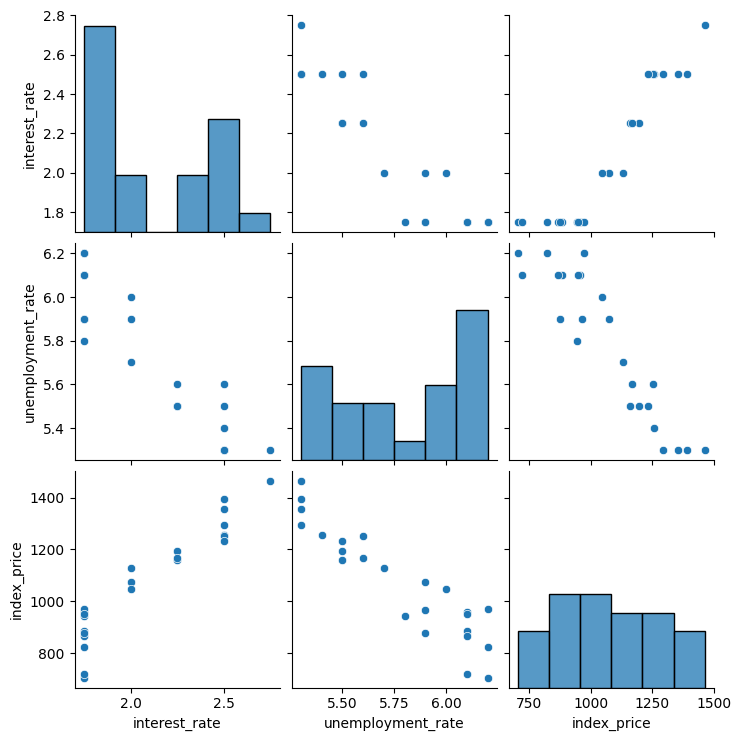

In [33]:
#Lets do some visu
import seaborn as sns
sns.pairplot(df)

In [34]:
df.corr()

,interest_rate,unemployment_rate,index_price
interest_rate,1.000000,-0.925814,0.935793
unemployment_rate,-0.925814,1.000000,-0.922338
index_price,0.935793,-0.922338,1.000000


Text(0, 0.5, 'unemployment_rate')

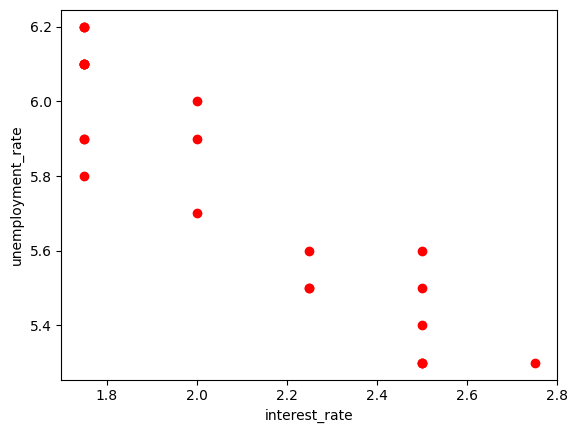

In [35]:
#visualise data point more closely
plt.scatter(df['interest_rate'],df['unemployment_rate'],color='r')
plt.xlabel('interest_rate')
plt.ylabel('unemployment_rate')

In [36]:
## independent and dependent features
X = df.drop(columns=['unemployment_rate'],axis=1)
y = df['unemployment_rate']

In [37]:
X


,interest_rate,index_price
0,2.75,1464
1,2.50,1394
2,2.50,1357
3,2.50,1293
4,2.50,1256
5,2.50,1254
6,2.50,1234
7,2.25,1195
8,2.25,1159
9,2.25,1167


In [38]:
#train test split
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=42)

In [39]:
import seaborn as sns

<Axes: xlabel='interest_rate', ylabel='unemployment_rate'>

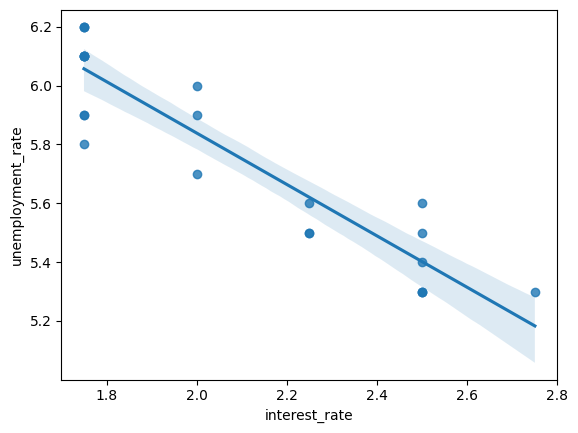

In [40]:
sns.regplot(x='interest_rate',y='unemployment_rate',data=df)

In [41]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [42]:
X_train

array([[-0.90115511, -0.41966146],
       [ 1.31077107,  1.6159075 ],
       [-0.90115511, -1.09818444],
       [ 1.31077107,  0.95161926],
       [ 1.31077107,  1.44034561],
       [-0.16384638, -0.03057835],
       [-0.90115511, -0.45287587],
       [ 1.31077107,  1.13667099],
       [ 1.31077107,  0.96110909],
       [-0.90115511, -1.65808453],
       [-0.90115511, -0.49558011],
       [-0.90115511, -0.84195898],
       [-0.90115511, -1.58691079],
       [ 0.57346234,  0.67166922],
       [-0.16384638,  0.36324968],
       [-0.90115511, -0.52404961],
       [-0.90115511, -0.88940814],
       [ 1.31077107,  0.85672094]])

In [43]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [44]:
lr.fit(X_train,y_train)

LinearRegression()

In [45]:
from sklearn.model_selection import cross_val_score
score = cross_val_score(lr,X_train,y_train,scoring="neg_mean_squared_error",cv=3)

In [46]:
score

array([-0.01876976, -0.01854254, -0.01390326])

In [47]:
np.mean(score)

np.float64(-0.017071853914476288)

In [48]:
#prediction
y_pred =  lr.predict(X_test)

In [49]:
y_pred

array([5.61410282, 5.95740134, 5.1620064 , 6.03830234, 5.77645311,
       5.60666365])

In [50]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print(mean_absolute_error(y_test,y_pred))
print(mean_squared_error(y_test,y_pred))
print(np.sqrt(mean_squared_error(y_test,y_pred)))


0.11443387941986034
0.018338439486580666
0.13541949448502852


In [51]:
from sklearn.metrics import r2_score
r2_score(y_test,y_pred)

0.8262674153902885

In [52]:
#display adjusted r2



AttributeError: 'float' object has no attribute 'round'

Text(0, 0.5, 'y_pred')

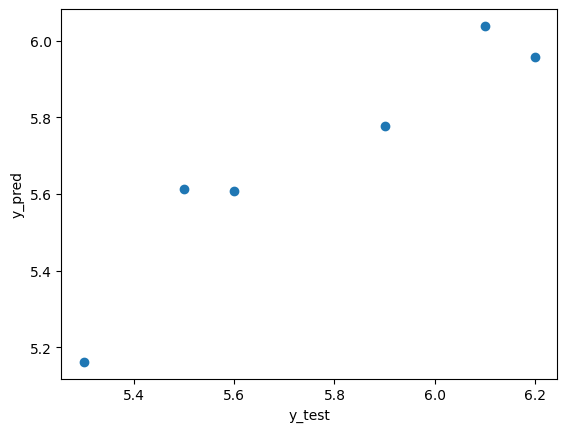

In [53]:
##Assumptions
plt.scatter(y_test,y_pred)
plt.xlabel("y_test")
plt.ylabel("y_pred")
#linear relation means model performed well

In [54]:
residuals = y_test-y_pred
print(residuals)

8    -0.114103
16    0.242599
0     0.137994
18    0.061698
11    0.123547
9    -0.006664
Name: unemployment_rate, dtype: float64


/tmp/ipykernel_1161/2998397011.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(residuals, kde=True)


<Axes: xlabel='unemployment_rate', ylabel='Density'>

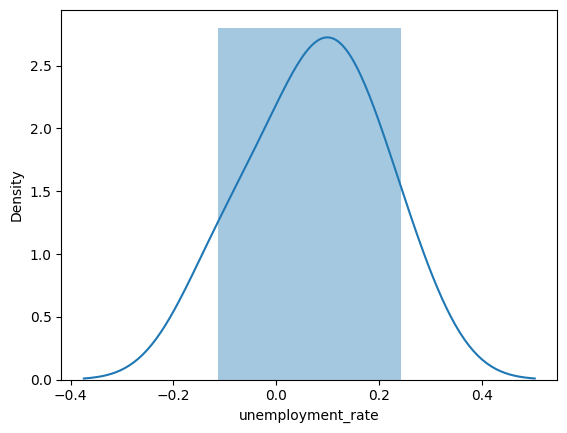

In [57]:
sns.distplot(residuals, kde=True)